# EDA — StudyOS documents
Explore page counts, text lengths, and token estimates.

In [4]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_parquet("../data/processed/squad_sample.parquet")
print(df.shape)
df.head()

(500, 3)


,context,question,answer
0,"Architecturally, the school has a Catholic cha...",To whom did the Virgin Mary allegedly appear i...,[Saint Bernadette Soubirous]
1,"Architecturally, the school has a Catholic cha...",What is in front of the Notre Dame Main Building?,[a copper statue of Christ]
2,"Architecturally, the school has a Catholic cha...",The Basilica of the Sacred heart at Notre Dame...,[the Main Building]
3,"Architecturally, the school has a Catholic cha...",What is the Grotto at Notre Dame?,[a Marian place of prayer and reflection]
4,"Architecturally, the school has a Catholic cha...",What sits on top of the Main Building at Notre...,[a golden statue of the Virgin Mary]


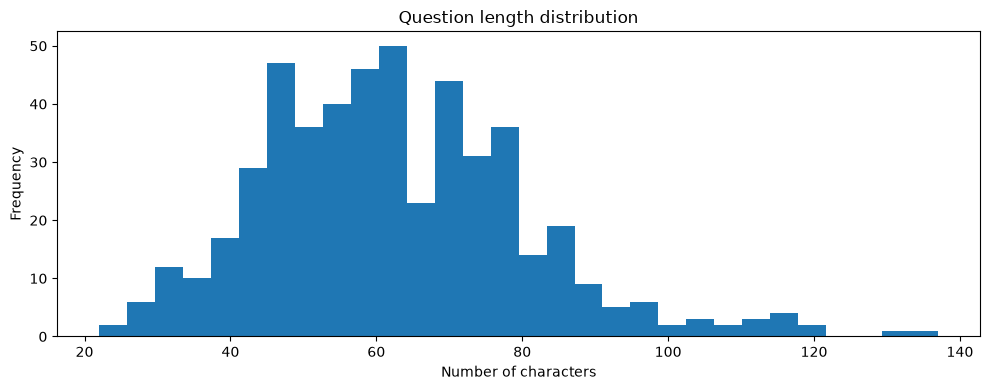

In [6]:
question_lengths = df["question"].str.len()

question_lengths.plot(
    kind="hist",
    bins=30,
    figsize=(10, 4),
    title="Question length distribution",
)

plt.xlabel("Number of characters")
plt.tight_layout()
plt.show()

count     500.000000
mean      954.640000
std       349.561945
min       427.000000
25%       694.000000
50%       877.000000
75%      1155.750000
max      1895.000000
Name: context, dtype: float64


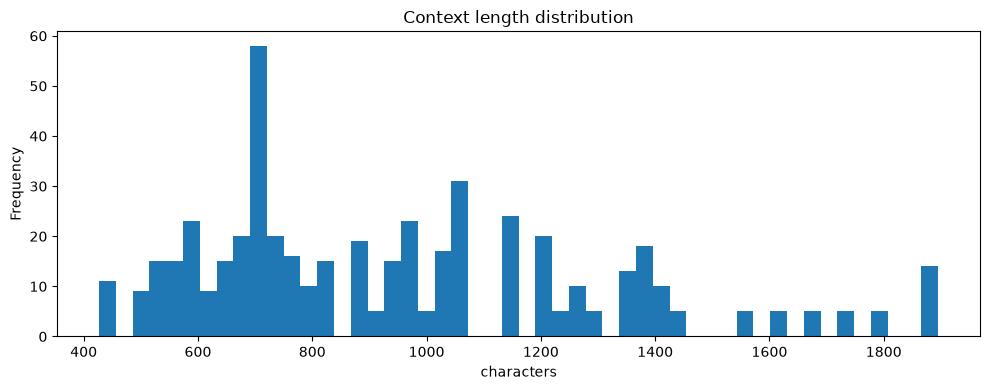

In [8]:
context_lengths = df["context"].str.len()
print(context_lengths.describe())

context_lengths.plot(
    kind="hist",
    bins=50,
    figsize=(10, 4),
    title="Context length distribution",
)
plt.xlabel("characters")
plt.tight_layout()
plt.show()

In [9]:
df["estimated_context_tokens"] = (df["context"].str.len() / 4).astype(int)
print("Total estimated context tokens:", df["estimated_context_tokens"].sum())
print("Average estimated context tokens:", round(df["estimated_context_tokens"].mean(), 1))

sample = df.sample(1, random_state=42).iloc[0]
print("Question:", sample["question"])
print("Answer:", sample["answer"])
print("Context:", sample["context"][:800])

Total estimated context tokens: 119142
Average estimated context tokens: 238.3
Question: When did Destiny's Child release their second album?
Answer: ['1999']
Context: The group changed their name to Destiny's Child in 1996, based upon a passage in the Book of Isaiah. In 1997, Destiny's Child released their major label debut song "Killing Time" on the soundtrack to the 1997 film, Men in Black. The following year, the group released their self-titled debut album, scoring their first major hit "No, No, No". The album established the group as a viable act in the music industry, with moderate sales and winning the group three Soul Train Lady of Soul Awards for Best R&B/Soul Album of the Year, Best R&B/Soul or Rap New Artist, and Best R&B/Soul Single for "No, No, No". The group released their multi-platinum second album The Writing's on the Wall in 1999. The record features some of the group's most widely known songs such as "Bills, Bills, Bills", the group's
